# 02 - Baseline and core models
**Milestone 3.** Lead: Ajwan (Modelling lead).

Every model is a full `Pipeline` (preprocessing + model) and is scored with the **same** 5-fold `TimeSeriesSplit` (24-row gap) on the training data. The test set is not used here.

In [1]:
# Setup: make the project root importable (works in Jupyter and in Colab
# after `%cd <repo>/notebooks`).
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.utils import *
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

def save(fig, name):
    """Save a figure to report/figures so it can go straight into the report."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160)
    plt.show()

In [2]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.compose import TransformedTargetRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

train, _ = load_split()
X, y = xy(train)

In [3]:
models = {
    "Mean baseline":              pipeline(DummyRegressor(strategy="mean")),
    "Linear Regression":          pipeline(LinearRegression()),
    # same model, but trained on log(1+cnt) and transformed back for scoring
    "Linear Regression (log y)":  TransformedTargetRegressor(
                                      regressor=pipeline(LinearRegression()),
                                      func=np.log1p, inverse_func=np.expm1),
    "Ridge (alpha=1)":            pipeline(Ridge(alpha=1.0)),
    "k-NN (k=10)":                pipeline(KNeighborsRegressor(n_neighbors=10)),
    "Decision Tree":              pipeline(DecisionTreeRegressor(random_state=SEED), kind="tree"),
}

rows = [cv_scores(name, model, X, y) for name, model in models.items()]
core = pd.DataFrame(rows)
core.to_csv(RESULTS / "core_model_results.csv", index=False)
core[["Model", "val_RMSE_mean", "val_RMSE_std", "val_MAE_mean", "val_R2_mean",
      "train_RMSE_mean", "train_R2_mean"]]

,Model,val_RMSE_mean,val_RMSE_std,val_MAE_mean,val_R2_mean,train_RMSE_mean,train_R2_mean
0,Mean baseline,180.623,42.739,138.158,-0.214,122.965,0.000
1,Linear Regression,109.046,19.532,80.592,0.542,68.964,0.684
2,Linear Regression (log y),113.527,30.754,76.504,0.511,65.206,0.715
3,Ridge (alpha=1),109.117,19.597,80.681,0.542,68.966,0.684
4,k-NN (k=10),132.771,28.460,99.110,0.333,70.630,0.659
5,Decision Tree,95.433,21.538,62.041,0.642,0.165,1.000


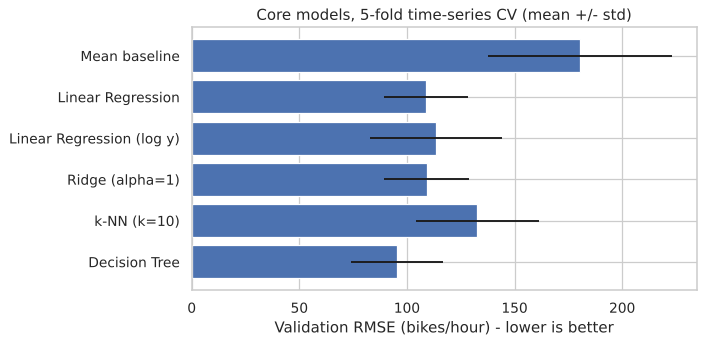

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(core["Model"], core["val_RMSE_mean"], xerr=core["val_RMSE_std"], color="#4C72B0")
ax.invert_yaxis()
ax.set(xlabel="Validation RMSE (bikes/hour) - lower is better",
       title="Core models, 5-fold time-series CV (mean +/- std)")
save(fig, "fig7_core_models.png")

### Why these models (suitability / weakness)
| Model | Why suitable here | Weakness |
|---|---|---|
| Mean baseline | Reference point: any useful model must beat it | Ignores all inputs |
| Linear Regression | Simple, fast, interpretable; with one-hot hour it can learn the daily profile | Cannot model interactions (hour x working day) or non-linear weather effects; can predict negative counts |
| Linear Regression (log y) | Handles the skewed target and multiplicative effects; predictions are always positive | Errors on busy hours are magnified when transforming back |
| Ridge | Linear model with L2 penalty; stable when features are correlated (`temp`/`atemp`, one-hot columns) | Same linear limits as linear regression |
| k-NN | Non-parametric; similar hours/weather -> similar demand | Slow at prediction time, sensitive to scaling and to the many one-hot dimensions |
| Decision Tree | Captures interactions and thresholds naturally, no scaling needed | A single deep tree overfits (high variance) - compare train vs validation |

### Results discussion
All models beat the mean baseline (validation RMSE 180.6). Linear regression reaches 109.0; Ridge gives the same result (109.1), so the correlated features were not a real problem for prediction. The log target lowers MAE (76.5 vs 80.6) but raises RMSE (113.5) and its spread: it fits typical hours better but misses busy hours by more after transforming back. k-NN is the weakest real model (132.8), probably because of the 60 one-hot dimensions. The decision tree is best here (95.4) but has a training RMSE of 0.2 and R² = 1.00 against a validation R² of 0.64: clear over-fitting (high variance), which motivates ensembles. The standard deviation across folds is large for every model (about 20-30) because the early folds train on only a few months of 2011 and the later folds must predict the busier 2012.